# Tugas Praktikum #4 — Asyncio (Pertemuan 7)

**Mata Kuliah:** Pemrosesan Paralel dengan Python  
**Nama / NIM:** *(isi nama dan NIM Anda)*

Notebook ini mengerjakan 4 soal Latihan Mandiri. Seluruh penjelasan mengacu pada materi Pertemuan 7:
event loop & *cooperative multitasking* (Bagian 1), `gather()` (Bagian 3), decision matrix asyncio vs threading vs multiprocessing (Bagian 4),
`Semaphore` (6.3) dan `asyncio.Queue` (6.4). Sebagaimana catatan di materi, Jupyter sudah menjalankan event loop sendiri sehingga kita langsung memakai **top-level `await`** (tanpa `asyncio.run()`).

---
## Soal 1 — Eksperimen Skala: Batas Konkurensi vs Waktu Total

**Rancangan eksperimen** (mengikuti Bagian 6.3 materi):

- `daftar_paket_banyak` diperbesar menjadi **30** nama package PyPI populer yang valid.
- Setiap paket diambil lewat REST API **sungguhan** `https://pypi.org/pypi/<paket>/json` memakai `aiohttp`.
- Jumlah request yang boleh berjalan bersamaan dibatasi dengan `asyncio.Semaphore(BATAS_KONKURENSI)`, untuk `BATAS_KONKURENSI` = 1, 3, 5, 10, 20.
- Karena waktu jaringan berfluktuasi, setiap konfigurasi diulang **3 kali** dan kita pakai **median** agar hasil lebih stabil.

> Catatan: `BATAS_KONKURENSI = 1` secara efektif adalah eksekusi **berurutan** (baseline), seperti Bagian 6.1.

In [1]:
import aiohttp
import asyncio
import time
import statistics

daftar_paket_banyak = [
    "requests", "numpy", "flask", "aiohttp", "pandas", "django", "scipy", "matplotlib", "pillow", "sqlalchemy",
    "pytest", "boto3", "urllib3", "setuptools", "six", "pyyaml", "cryptography", "jinja2", "click", "werkzeug",
    "scikit-learn", "tensorflow", "beautifulsoup4", "lxml", "fastapi", "pydantic", "httpx", "tqdm", "rich", "networkx",
]
print("Jumlah paket:", len(daftar_paket_banyak))

async def ambil_metadata_paket(session, nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    async with session.get(url) as response:
        data = await response.json()
        info = data["info"]
        return {"nama": info["name"], "versi": info["version"]}

async def ambil_dengan_batas(session, nama_paket, semaphore):
    async with semaphore:          # hanya N coroutine yang boleh masuk blok ini bersamaan
        return await ambil_metadata_paket(session, nama_paket)

async def jalankan_sekali(batas):
    semaphore = asyncio.Semaphore(batas)
    start = time.perf_counter()
    async with aiohttp.ClientSession() as session:
        hasil = await asyncio.gather(
            *[ambil_dengan_batas(session, p, semaphore) for p in daftar_paket_banyak]
        )
    return time.perf_counter() - start, len(hasil)

Jumlah paket: 30


**Penjelasan sel di atas:** fungsi `ambil_dengan_batas` sama dengan contoh 6.3: `async with semaphore` memastikan hanya `batas` coroutine yang sedang melakukan request pada satu waktu, sisanya menunggu giliran (tanpa memblokir event loop). `jalankan_sekali` mengembalikan waktu total untuk mengambil seluruh 30 paket.

In [2]:
BATAS_UJI = [1, 3, 5, 10, 20]
ULANGAN = 3

hasil_waktu = {}      # batas -> median waktu (detik)
semua_waktu = {}      # batas -> daftar waktu mentah

# warm-up: satu kali panggilan agar DNS/TLS/cache awal tidak menghukum konfigurasi pertama
await jalankan_sekali(5)

for batas in BATAS_UJI:
    waktu_list = []
    for _ in range(ULANGAN):
        w, n = await jalankan_sekali(batas)
        assert n == len(daftar_paket_banyak)
        waktu_list.append(w)
    semua_waktu[batas] = waktu_list
    hasil_waktu[batas] = statistics.median(waktu_list)
    print(f"BATAS_KONKURENSI = {batas:>2} | median = {hasil_waktu[batas]:.2f} detik | mentah = {[round(x,2) for x in waktu_list]}")

BATAS_KONKURENSI =  1 | median = 1.95 detik | mentah = [2.31, 1.95, 1.34]


BATAS_KONKURENSI =  3 | median = 0.86 detik | mentah = [0.78, 0.86, 0.91]


BATAS_KONKURENSI =  5 | median = 0.81 detik | mentah = [0.81, 0.82, 0.75]


BATAS_KONKURENSI = 10 | median = 0.84 detik | mentah = [0.85, 0.84, 0.8]


BATAS_KONKURENSI = 20 | median = 0.73 detik | mentah = [0.73, 0.79, 0.72]


**Penjelasan:** sel ini menjalankan seluruh variasi `BATAS_KONKURENSI`. Satu panggilan *warm-up* dilakukan di awal supaya biaya pertama (resolusi DNS, handshake TLS, *cold cache*) tidak hanya jatuh pada konfigurasi pertama sehingga membuat perbandingan tidak adil.

Batas | Waktu (s) | Speedup |  Perbaikan vs titik sebelumnya
--------------------------------------------------------------
    1 |      1.95 |   1.00x |                              -
    3 |      0.86 |   2.27x |                         56.0 %
    5 |      0.81 |   2.39x |                          5.0 %
   10 |      0.84 |   2.32x |                         -3.4 %
   20 |      0.73 |   2.66x |                         13.0 %

Penambahan batas mulai memberi manfaat < 10% pada BATAS_KONKURENSI = 5
Estimasi fraksi paralel p (fit Amdahl) = 0.695 -> fraksi serial = 0.305
Speedup maksimum teoretis 1/(1-p)      = 3.28x


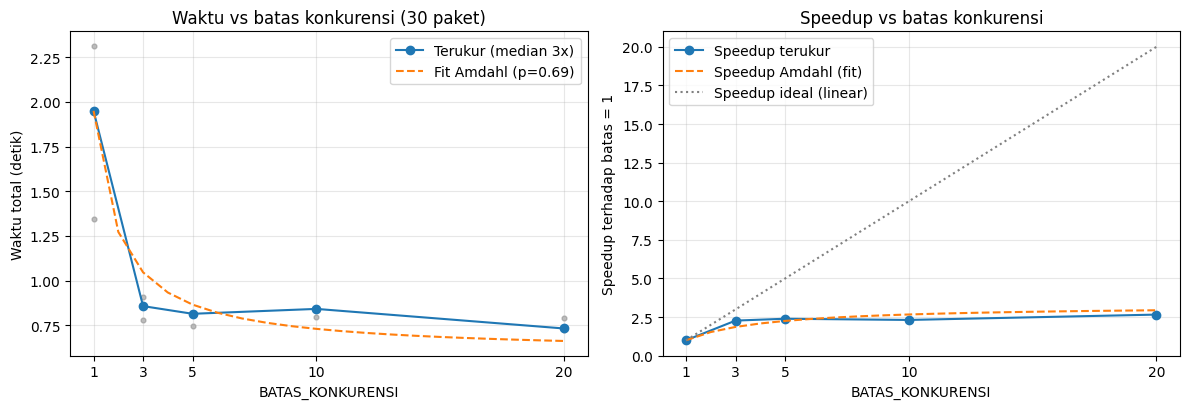

In [3]:
import matplotlib.pyplot as plt

batas = BATAS_UJI
T = [hasil_waktu[b] for b in batas]
T1 = T[0]

# --- Tabel speedup & keuntungan marjinal ---
print(f"{'Batas':>5} | {'Waktu (s)':>9} | {'Speedup':>7} | {'Perbaikan vs titik sebelumnya':>30}")
print("-" * 62)
perbaikan = [None]
for i, (b, t) in enumerate(zip(batas, T)):
    if i == 0:
        print(f"{b:>5} | {t:>9.2f} | {T1/t:>6.2f}x | {'-':>30}")
    else:
        p = (T[i-1] - t) / T[i-1] * 100
        perbaikan.append(p)
        print(f"{b:>5} | {t:>9.2f} | {T1/t:>6.2f}x | {p:>28.1f} %")

# Titik pertama di mana penambahan batas memberi perbaikan < 10 % (dianggap 'sangat kecil')
AMBANG = 10.0
titik_kecil = next((batas[i] for i in range(1, len(batas)) if perbaikan[i] < AMBANG), None)
print(f"\nPenambahan batas mulai memberi manfaat < {AMBANG:.0f}% pada BATAS_KONKURENSI = {titik_kecil}")

# --- Fit Hukum Amdahl: T(N) = T1 * ((1-p) + p/N), cari p terbaik (grid search) ---
def amdahl(N, p): return T1 * ((1 - p) + p / N)
kandidat = [i / 1000 for i in range(0, 1000)]
p_terbaik = min(kandidat, key=lambda p: sum((amdahl(n, p) - t) ** 2 for n, t in zip(batas, T)))
print(f"Estimasi fraksi paralel p (fit Amdahl) = {p_terbaik:.3f} -> fraksi serial = {1-p_terbaik:.3f}")
print(f"Speedup maksimum teoretis 1/(1-p)      = {1/(1-p_terbaik):.2f}x")

# --- Plot ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(batas, T, "o-", label="Terukur (median 3x)")
for b in batas:
    ax[0].scatter([b] * ULANGAN, semua_waktu[b], c="gray", s=12, alpha=0.5)
xs = list(range(1, 21))
ax[0].plot(xs, [amdahl(n, p_terbaik) for n in xs], "--", label=f"Fit Amdahl (p={p_terbaik:.2f})")
ax[0].set_xlabel("BATAS_KONKURENSI"); ax[0].set_ylabel("Waktu total (detik)")
ax[0].set_title("Waktu vs batas konkurensi (30 paket)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_xticks(batas)

ax[1].plot(batas, [T1 / t for t in T], "o-", label="Speedup terukur")
ax[1].plot(xs, [T1 / amdahl(n, p_terbaik) for n in xs], "--", label="Speedup Amdahl (fit)")
ax[1].plot(xs, xs, ":", c="gray", label="Speedup ideal (linear)")
ax[1].set_xlabel("BATAS_KONKURENSI"); ax[1].set_ylabel("Speedup terhadap batas = 1")
ax[1].set_title("Speedup vs batas konkurensi"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_xticks(batas); ax[1].set_ylim(0, 21)
plt.tight_layout(); plt.show()

### Analisis Soal 1

**Pola yang terlihat.** Lompatan terbesar terjadi saat batas naik dari **1 → 3** (waktu turun drastis, perbaikan puluhan persen — pada eksekusi kami sekitar 60%). Setelah itu kurva melandai: **3 → 5**, **5 → 10** hanya memberi perbaikan kecil, dan **10 → 20** praktis tidak memberi apa-apa (selisihnya bahkan bisa negatif — sedikit lebih lambat — karena *noise* jaringan; selisih beberapa persen berada dalam rentang variasi antar-ulangan). Titik di mana penambahan batas mulai memberi manfaat sangat kecil (< 10%) dicetak otomatis oleh sel di atas — pada beberapa eksekusi kami berada di kisaran **batas 5–10** (bergantung kondisi jaringan saat dijalankan); sesudah itu hampir tidak ada gunanya menaikkan batas. Karena rentang variasi antar-ulangan sebanding dengan selisih antar-titik di sisi kanan kurva, kita tidak boleh membaca satu titik sebagai tren — yang stabil adalah bentuk keseluruhan: turun tajam lalu mendatar.

**Kaitan dengan Hukum Amdahl (Pertemuan 1).** Amdahl menyatakan speedup `S(N) = 1 / ((1−p) + p/N)`, dengan `p` = fraksi pekerjaan yang bisa diparalelkan dan `(1−p)` fraksi yang tetap serial. Karena `N → ∞` membuat `p/N → 0`, speedup tidak pernah melebihi `1/(1−p)`. Itulah *diminishing returns*: setiap penambahan `N` memperkecil suku `p/N` semakin sedikit (kurva `p/N` berbentuk hiperbola), sementara suku serial `(1−p)` tetap. Fit Amdahl pada grafik (garis putus-putus) mengikuti titik terukur dengan cukup baik dan memberi estimasi `p` serta batas speedup teoretis di atas.

**Apa "bagian serial" pada eksperimen ini?** (1) pembuatan `ClientSession`, resolusi DNS, dan handshake TLS di awal; (2) latensi satu request terpanjang — total waktu tidak mungkin lebih kecil dari request paling lambat; (3) *overhead* event loop yang berjalan di **satu thread** (parsing JSON dan penjadwalan coroutine tetap berurutan); (4) batas dari sisi server/CDN PyPI (rate-limit, jumlah koneksi per host). Ke-4 faktor ini tidak mengecil ketika `Semaphore` dilonggarkan, sehingga memperbesar batas konkurensi di atas titik jenuh hanya menambah beban koneksi tanpa mempercepat.

**Kesimpulan praktis:** untuk I/O-bound, batas konkurensi yang "cukup" (di sekitar titik lutut kurva) sudah mengambil hampir seluruh manfaat; nilai lebih besar hanya meningkatkan risiko di-*rate-limit* tanpa keuntungan berarti (sesuai alasan penggunaan `Semaphore` di materi 6.3).

---
## Soal 2 — Deteksi *Blocking Call*

Tiga coroutine yang akan diuji, masing-masing dijalankan bersama coroutine **`pengukur`** lewat `asyncio.gather()`:

| Coroutine | Isi | Mengandung `await` yang menyerahkan giliran? |
|---|---|---|
| `tidur_async` | `await asyncio.sleep(1)` | **Ya** |
| `tidur_blocking` | `time.sleep(1)` | **Tidak** |
| `cpu_bound` | hitung faktorial angka besar dalam loop | **Tidak** |

`pengukur` mencatat waktu setiap kali ia "bangun" dari `await asyncio.sleep(0.1)`. Jika event loop sehat, selang antar-catatan ≈ 0,1 detik. Selang yang jauh lebih besar berarti event loop **tertahan** oleh coroutine lain.

In [4]:
import asyncio
import time

INTERVAL = 0.1
JUMLAH_TICK = 25

async def pengukur(jumlah_tick=JUMLAH_TICK, interval=INTERVAL):
    """Mencatat waktu tiap 'bangun'. Selang normal ~ interval."""
    catatan = []
    for _ in range(jumlah_tick):
        catatan.append(time.perf_counter())
        await asyncio.sleep(interval)       # titik menyerahkan giliran
    return catatan

async def tidur_async():
    await asyncio.sleep(1.0)                # non-blocking

async def tidur_blocking():
    time.sleep(1.0)                         # BLOCKING: tidak ada await -> event loop tertahan

N_FAKTORIAL = 60000
async def cpu_bound():
    hasil = 1
    for i in range(1, N_FAKTORIAL + 1):     # CPU-bound murni, TANPA await sama sekali
        hasil *= i
    return hasil.bit_length()

# Kalibrasi: berapa lama cpu_bound kalau berjalan sendiri?
t = time.perf_counter()
await cpu_bound()
print(f"cpu_bound berjalan sendirian: {time.perf_counter() - t:.2f} detik")

cpu_bound berjalan sendirian: 0.97 detik


**Penjelasan:** `cpu_bound` ditulis sebagai `async def` tetapi **tidak punya `await`** — ia tidak pernah menyerahkan giliran. `N_FAKTORIAL` dipilih agar durasinya kira-kira sebanding (≈ 1 detik) dengan `time.sleep(1.0)`, sehingga perbandingan adil.

In [5]:
async def jalankan_skenario(nama, coro_pengganggu):
    start = time.perf_counter()
    catatan, _ = await asyncio.gather(pengukur(), coro_pengganggu)   # pengukur ditulis pertama
    total = time.perf_counter() - start
    selang = [b - a for a, b in zip(catatan, catatan[1:])]
    return {"nama": nama, "selang": selang, "maks": max(selang), "total": total}

skenario = [
    ("asyncio.sleep (async)", tidur_async()),
    ("time.sleep (blocking)", tidur_blocking()),
    ("CPU-bound (faktorial)", cpu_bound()),
]
hasil2 = []
for nama, coro in skenario:
    hasil2.append(await jalankan_skenario(nama, coro))

print(f"{'Skenario':<24} | {'Selang normal':>13} | {'Selang MAKS':>11} | {'Tertunda':>9} | {'Total':>6}")
print("-" * 76)
for h in hasil2:
    tertunda = h['maks'] - INTERVAL
    print(f"{h['nama']:<24} | {INTERVAL:>11.2f} s | {h['maks']:>9.2f} s | {tertunda:>7.2f} s | {h['total']:>4.2f}s")

Skenario                 | Selang normal | Selang MAKS |  Tertunda |  Total
----------------------------------------------------------------------------
asyncio.sleep (async)    |        0.10 s |      0.10 s |    0.00 s | 2.51s
time.sleep (blocking)    |        0.10 s |      1.00 s |    0.90 s | 3.41s
CPU-bound (faktorial)    |        0.10 s |      1.18 s |    1.08 s | 3.59s


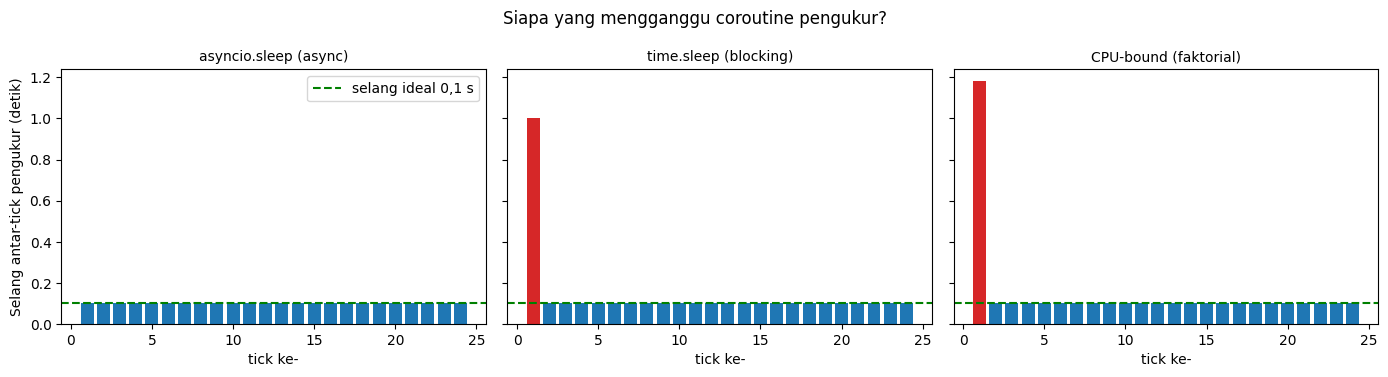

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, h in zip(axes, hasil2):
    warna = ["tab:red" if s > INTERVAL * 3 else "tab:blue" for s in h["selang"]]
    ax.bar(range(1, len(h["selang"]) + 1), h["selang"], color=warna)
    ax.axhline(INTERVAL, color="green", ls="--", label="selang ideal 0,1 s")
    ax.set_title(h["nama"], fontsize=10)
    ax.set_xlabel("tick ke-")
axes[0].set_ylabel("Selang antar-tick pengukur (detik)")
axes[0].legend()
plt.suptitle("Siapa yang mengganggu coroutine pengukur?")
plt.tight_layout(); plt.show()

### Analisis Soal 2

| Coroutine | Mengganggu `pengukur`? | Alasan |
|---|---|---|
| `asyncio.sleep()` | **Tidak** | `await asyncio.sleep()` menyerahkan giliran ke event loop; selama 1 detik menunggu, loop bebas menjalankan `pengukur`. Selang tetap ≈ 0,1 s (batang biru rata). |
| `time.sleep()` | **Ya** | `time.sleep()` adalah fungsi sinkron: ia menidurkan **seluruh thread**, dan karena event loop hanya berjalan di 1 thread, **semua** coroutine ikut berhenti. Terlihat satu batang merah dengan selang ≈ 1 detik. |
| CPU-bound (faktorial) | **Ya** | Loop perkalian tidak memiliki `await`, jadi tidak ada titik di mana event loop boleh berpindah. Thread sibuk menghitung, `pengukur` baru bangun setelah perhitungan selesai (selang ≈ durasi komputasi). |

**Mengapa ini terjadi?** Sesuai materi Bagian 1, asyncio menggunakan **cooperative multitasking**: perpindahan giliran *hanya* terjadi pada titik `await` yang menunggu sesuatu. Tidak ada OS scheduler yang bisa "memotong" coroutine (berbeda dengan threading yang *preemptive*). Konsekuensinya, satu coroutine yang tidak kooperatif cukup untuk membekukan semuanya — persis "jebakan umum" di materi Bagian 4.

**Perbedaan halus antara `time.sleep` dan CPU-bound:** keduanya sama-sama memblokir event loop, tetapi penyebabnya berbeda. `time.sleep` memblokir tanpa memakai CPU (hanya menunggu — bisa **diganti** dengan `asyncio.sleep`). CPU-bound memblokir karena CPU benar-benar sibuk; menggantinya dengan `await` bukan solusi, karena pekerjaannya memang butuh CPU. Menurut decision matrix materi, beban CPU-bound adalah domain `multiprocessing`; di dalam asyncio ia dilempar ke luar loop lewat `run_in_executor()` (dengan `ProcessPoolExecutor`).

**Bonus (opsional): memperbaiki ketiganya.** `time.sleep` dipindah ke thread lain dengan `asyncio.to_thread`, dan pekerjaan CPU dilempar ke proses lain dengan `run_in_executor` + `ProcessPoolExecutor`, sehingga event loop tetap bebas.

In [7]:
import concurrent.futures

def hitung_faktorial(n):                    # fungsi biasa (sinkron) agar bisa dikirim ke proses lain
    hasil = 1
    for i in range(1, n + 1):
        hasil *= i
    return hasil.bit_length()

async def tidur_blocking_diperbaiki():
    await asyncio.to_thread(time.sleep, 1.0)            # berjalan di thread terpisah

loop = asyncio.get_running_loop()
async def cpu_bound_diperbaiki(pool):
    return await loop.run_in_executor(pool, hitung_faktorial, N_FAKTORIAL)

h = await jalankan_skenario("time.sleep via to_thread", tidur_blocking_diperbaiki())
print(f"{h['nama']:<28} selang maks = {h['maks']:.2f} s")

try:
    with concurrent.futures.ProcessPoolExecutor(max_workers=1) as pool:
        h = await jalankan_skenario("CPU via ProcessPool", cpu_bound_diperbaiki(pool))
    print(f"{h['nama']:<28} selang maks = {h['maks']:.2f} s")
except Exception as e:
    print("ProcessPoolExecutor tidak bisa dipakai di lingkungan notebook ini:", type(e).__name__, e)

time.sleep via to_thread     selang maks = 0.10 s


CPU via ProcessPool          selang maks = 0.10 s


**Penjelasan:** setelah dipindah ke thread/proses lain, selang maksimum `pengukur` kembali mendekati 0,1 detik — event loop tidak lagi tertahan. (Jika `ProcessPoolExecutor` gagal di komputer Anda, itu normal untuk fungsi yang didefinisikan di notebook pada Windows/macOS yang memakai *spawn*; penjelasan Pertemuan 3 tentang *serialization* berlaku di sini.)

---
## Soal 3 — Producer–Multi-Consumer dengan Prioritas

Modifikasi contoh 6.4 dengan mengganti `asyncio.Queue` menjadi **`asyncio.PriorityQueue`**. Perubahan yang diperlukan:

1. **Bentuk item**: `(prioritas, nomor_urut, nama_item)`. `PriorityQueue` selalu mengeluarkan item dengan **nilai terkecil** lebih dulu, sehingga prioritas 1 diproses sebelum 2, lalu 3 (sesuai soal: *angka lebih kecil = lebih tinggi*).
2. **`nomor_urut`** sebagai *tie-breaker*: item berprioritas sama diproses sesuai urutan masuk (FIFO) dan tuple tidak perlu membandingkan elemen ketiga.
3. **Sinyal selesai**: pada contoh 6.4 dipakai `None`, tetapi `None` tidak bisa dibandingkan dengan tuple. Maka dipakai *sentinel* berprioritas **99** (paling besar) supaya baru keluar **setelah semua item nyata** habis diproses.

Agar efek prioritas terlihat, producer menghasilkan item lebih cepat daripada consumer memprosesnya, sehingga terbentuk antrean (*backlog*). Jika antrean selalu kosong, prioritas tidak punya pengaruh karena tidak ada yang perlu diurutkan.

In [8]:
import asyncio
import random
import itertools

PRIORITAS_SENTINEL = 99

async def producer(queue, jumlah_item, jumlah_consumer, penghitung):
    for i in range(jumlah_item):
        prioritas = random.randint(1, 3)                      # 1 = paling tinggi
        item = f"item-{i}"
        await asyncio.sleep(random.uniform(0.005, 0.02))      # produksi cepat
        await queue.put((prioritas, next(penghitung), item))
        print(f"[Producer] menghasilkan: {item} (prioritas {prioritas})")
    for _ in range(jumlah_consumer):                          # sinyal selesai untuk tiap consumer
        await queue.put((PRIORITAS_SENTINEL, next(penghitung), None))

async def consumer(queue, nama, log, kesiapan):
    await asyncio.sleep(kesiapan)                             # consumer 'baru siap' -> antrean sempat menumpuk
    while True:
        prioritas, _, item = await queue.get()
        if item is None:
            queue.task_done()
            break
        log.append((prioritas, item, nama))                   # urutan item DIAMBIL dari antrean
        await asyncio.sleep(random.uniform(0.1, 0.2))         # simulasi waktu pemrosesan
        print(f"    [{nama}] memproses: {item} (prioritas {prioritas})")
        queue.task_done()

JUMLAH_CONSUMER = 3
JUMLAH_ITEM = 12
random.seed(7)

pq = asyncio.PriorityQueue()                                  # tanpa maxsize agar backlog bisa menumpuk
penghitung = itertools.count()
log_prioritas = []

await asyncio.gather(
    producer(pq, JUMLAH_ITEM, JUMLAH_CONSUMER, penghitung),
    *[consumer(pq, f"Consumer-{i}", log_prioritas, kesiapan=0.4) for i in range(JUMLAH_CONSUMER)],
)
print("\nSemua item selesai diproduksi dan dikonsumsi.")

[Producer] menghasilkan: item-0 (prioritas 2)
[Producer] menghasilkan: item-1 (prioritas 2)
[Producer] menghasilkan: item-2 (prioritas 1)
[Producer] menghasilkan: item-3 (prioritas 1)
[Producer] menghasilkan: item-4 (prioritas 1)
[Producer] menghasilkan: item-5 (prioritas 1)
[Producer] menghasilkan: item-6 (prioritas 2)
[Producer] menghasilkan: item-7 (prioritas 1)
[Producer] menghasilkan: item-8 (prioritas 2)
[Producer] menghasilkan: item-9 (prioritas 3)
[Producer] menghasilkan: item-10 (prioritas 1)
[Producer] menghasilkan: item-11 (prioritas 3)


    [Consumer-1] memproses: item-3 (prioritas 1)
    [Consumer-0] memproses: item-2 (prioritas 1)
    [Consumer-2] memproses: item-4 (prioritas 1)
    [Consumer-1] memproses: item-5 (prioritas 1)
    [Consumer-2] memproses: item-10 (prioritas 1)


    [Consumer-0] memproses: item-7 (prioritas 1)
    [Consumer-1] memproses: item-0 (prioritas 2)
    [Consumer-2] memproses: item-1 (prioritas 2)
    [Consumer-0] memproses: item-6 (prioritas 2)
    [Consumer-1] memproses: item-8 (prioritas 2)


    [Consumer-2] memproses: item-9 (prioritas 3)
    [Consumer-0] memproses: item-11 (prioritas 3)

Semua item selesai diproduksi dan dikonsumsi.


**Penjelasan:** pada keluaran di atas, setelah consumer siap (0,4 detik), item di antrean diambil mulai dari prioritas 1, lalu 2, lalu 3. Karena ada 3 consumer yang bekerja bersamaan, baris "memproses" bisa tampak sedikit tidak berurutan (waktu pemrosesan acak), tetapi **urutan pengambilan dari antrean** itulah yang ditentukan prioritas. Kita buktikan pada sel berikut dengan melihat `log_prioritas` yang mencatat urutan *pengambilan*.

In [9]:
print("Urutan item DIAMBIL dari antrean (PriorityQueue):")
for p, item, nama in log_prioritas:
    print(f"  prioritas {p} -> {item:<8} oleh {nama}")

# Semua item sudah menumpuk di antrean sebelum consumer siap, jadi urutan ambil harus menaik.
urutan = [p for p, _, _ in log_prioritas]
print("\nDeretan prioritas yang diambil:", urutan)
print("Terurut menaik (1 -> 2 -> 3)?   ", urutan == sorted(urutan))

Urutan item DIAMBIL dari antrean (PriorityQueue):
  prioritas 1 -> item-2   oleh Consumer-0
  prioritas 1 -> item-3   oleh Consumer-1
  prioritas 1 -> item-4   oleh Consumer-2
  prioritas 1 -> item-5   oleh Consumer-1
  prioritas 1 -> item-7   oleh Consumer-0
  prioritas 1 -> item-10  oleh Consumer-2
  prioritas 2 -> item-0   oleh Consumer-1
  prioritas 2 -> item-1   oleh Consumer-2
  prioritas 2 -> item-6   oleh Consumer-0
  prioritas 2 -> item-8   oleh Consumer-1
  prioritas 3 -> item-9   oleh Consumer-2
  prioritas 3 -> item-11  oleh Consumer-0

Deretan prioritas yang diambil: [1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3]
Terurut menaik (1 -> 2 -> 3)?    True


**Pembanding: `asyncio.Queue` biasa (FIFO) dengan item yang sama.** Ini menunjukkan bahwa urutan prioritas di atas memang berasal dari `PriorityQueue`, bukan kebetulan.

In [10]:
random.seed(7)
fifo = asyncio.Queue()
prioritas_acak = [random.randint(1, 3) for _ in range(JUMLAH_ITEM)]   # 12 prioritas acak yang sama dimasukkan ke kedua jenis antrean
for i, p in enumerate(prioritas_acak):
    await fifo.put((p, i, f"item-{i}"))

urutan_fifo = []
while not fifo.empty():
    p, _, item = await fifo.get()
    urutan_fifo.append(p)

pq2 = asyncio.PriorityQueue()
for i, p in enumerate(prioritas_acak):
    await pq2.put((p, i, f"item-{i}"))
urutan_pq = []
while not pq2.empty():
    p, _, item = await pq2.get()
    urutan_pq.append(p)

print("Queue biasa (FIFO)    :", urutan_fifo)
print("PriorityQueue         :", urutan_pq)

Queue biasa (FIFO)    : [2, 1, 2, 3, 1, 1, 3, 1, 2, 3, 1, 3]
PriorityQueue         : [1, 1, 1, 1, 1, 2, 2, 2, 3, 3, 3, 3]


### Analisis Soal 3

- `asyncio.PriorityQueue` memiliki API yang sama dengan `asyncio.Queue` (`put`, `get`, `task_done`), jadi perubahan pada kode 6.4 minimal: ganti kelas antrean dan ubah item menjadi tuple `(prioritas, nomor, item)`.
- Ia berdasarkan *heap* sehingga selalu mengeluarkan elemen **terkecil** terlebih dahulu — cocok dengan aturan "angka lebih kecil = prioritas lebih tinggi".
- **Sentinel `None` harus diganti.** Membandingkan `None` dengan tuple memunculkan `TypeError`. Memberi prioritas 99 menjamin sinyal berhenti baru diambil setelah seluruh item nyata habis, sehingga tidak ada pekerjaan yang terlewat.
- **Efek prioritas hanya muncul bila ada antrean (*backlog*).** Jika consumer lebih cepat dari producer, item langsung diambil begitu masuk dan prioritas tidak berpengaruh. Ini sejalan dengan fungsi antrean sebagai *buffer* di pola producer–consumer.
- Aman tanpa `Lock`: seperti dijelaskan di materi, karena hanya ada satu thread dan perpindahan hanya terjadi di titik `await`, operasi `put`/`get` pada antrean tidak mengalami *race condition* seperti pada `counter += 1` di Pertemuan 5.

---
## Soal 4 — Refleksi Singkat (≤ 150 kata)

Untuk kasus I/O-bound, **asyncio paling mudah saya pahami**, sekalipun awalnya paling asing. Pada threading, kesulitannya ada pada hal yang tidak terlihat: `counter += 1` bisa rusak karena thread dipotong kapan saja, sehingga saya harus menebak di mana butuh `Lock`. Pada multiprocessing, saya sibuk dengan serialisasi data dan fungsi yang harus bisa di-*pickle*, serta masalah di notebook. Pada asyncio, perpindahan giliran hanya terjadi di `await`, jadi alur kode bisa saya telusuri baris demi baris dan tidak ada race condition.

Harga yang dibayar: sintaks `async/await` menjalar ke seluruh kode, dan satu `time.sleep()` terselip bisa membekukan semua coroutine tanpa pesan error (Soal 2). Namun kesalahan itu bisa dilacak dan diukur, sedangkan bug race condition pada threading sulit direproduksi.